Import required libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


upload and load the excel dataset

In [ ]:
from google.colab import files
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)
print("dataset loaded successfully!")
print("file name: ", file_name)
print("dataset shape: ", df.shape)

Saving foodtimedataset.xlsx to foodtimedataset (1).xlsx
dataset loaded successfully!
file name:  foodtimedataset (1).xlsx
dataset shape:  (10001, 17)


Dataset Overview

In [ ]:

print("\n1. First 5 Records:")
display(df.head())
print("\n2. Dataset Shape:")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("\n3. Column Names:")
print(df.columns.tolist())
print("\n4. Data Types:")
print(df.dtypes)
print("\n5. Dataset Information:")
df.info()


1. First 5 Records:


,ID,Delivery Person ID,Delivery Person Age,Delivery Person Ratings,Restaurant Latitude,Restaurant Longitude,Delivery Location Latitude,Delivery Location Longitude,Order Type,Vehicle Type,Temperature,Humidity,Precipitation,Weather Description,Traffic Level,Distance,Delivery Time
0,4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,Snack,motorcycle,17.11,77.0,0.0,haze,Low,NaN,21.666667
1,B379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,Snack,scooter,19.50,93.0,0.0,mist,Very High,37.17,85.266667
2,5D6D,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,Drinks,motorcycle,20.45,91.0,0.0,mist,Low,3.34,28.583333
3,7A6A,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,Buffet,motorcycle,23.86,78.0,0.0,mist,Moderate,10.05,35.183333
4,70A2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,Snack,scooter,26.55,87.0,0.0,mist,High,9.89,43.450000



2. Dataset Shape:
Total Rows: 10001
Total Columns: 17

3. Column Names:
['ID', 'Delivery Person ID', 'Delivery Person Age', 'Delivery Person Ratings', 'Restaurant Latitude', 'Restaurant Longitude', 'Delivery Location Latitude', 'Delivery Location Longitude', 'Order Type', 'Vehicle Type', 'Temperature', 'Humidity', 'Precipitation', 'Weather Description', 'Traffic Level', 'Distance', 'Delivery Time']

4. Data Types:
ID                              object
Delivery Person ID              object
Delivery Person Age            float64
Delivery Person Ratings        float64
Restaurant Latitude            float64
Restaurant Longitude           float64
Delivery Location Latitude     float64
Delivery Location Longitude    float64
Order Type                      object
Vehicle Type                    object
Temperature                    float64
Humidity                       float64
Precipitation                  float64
Weather Description             object
Traffic Level                   obj

Data Quality Check

In [ ]:
print("\n1. Missing Values in Each Column:")
print(df.isnull().sum())
print("\n2. Total Missing Values:")
print(df.isnull().sum().sum())
print("\n3. Duplicate Rows:")
print(df.duplicated().sum())
print("\n4. Duplicate Delivery IDs:")
if "ID" in df.columns:
    print(df["ID"].duplicated().sum())
else:
    print("ID column not found.")
print("\n5. Dataset Information:")
df.info()


1. Missing Values in Each Column:
ID                               1
Delivery Person ID               1
Delivery Person Age              1
Delivery Person Ratings          1
Restaurant Latitude              1
Restaurant Longitude             1
Delivery Location Latitude       1
Delivery Location Longitude      1
Order Type                       1
Vehicle Type                     1
Temperature                      6
Humidity                         6
Precipitation                    6
Weather Description              6
Traffic Level                  916
Distance                       921
Delivery Time                  961
dtype: int64

2. Total Missing Values:
2832

3. Duplicate Rows:
0

4. Duplicate Delivery IDs:
9

5. Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10001 entries, 0 to 10000
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                 

Data Cleaning

In [ ]:
df_clean = df.copy()
print("\nOriginal Dataset Shape:", df_clean.shape)

df_clean.dropna(how="all", inplace=True)

df_clean.drop_duplicates(inplace=True)

df_clean.dropna(subset=["ID"], inplace=True)


numerical_columns = [
    "Delivery Person Age",
    "Delivery Person Ratings",
    "Restaurant Latitude",
    "Restaurant Longitude",
    "Delivery Location Latitude",
    "Delivery Location Longitude",
    "Temperature",
    "Humidity",
    "Precipitation"
]

for column in numerical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

categorical_columns = [
    "Delivery Person ID",
    "Order Type",
    "Vehicle Type",
    "Weather Description",
    "Traffic Level"
]

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna("Unknown")

print("\nCleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nTotal Remaining Missing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Rows After Cleaning:")
print(df_clean.duplicated().sum())

print("\nData Cleaning Completed Successfully!")


Original Dataset Shape: (10001, 17)

Cleaned Dataset Shape: (10000, 17)

Missing Values After Cleaning:
ID                               0
Delivery Person ID               0
Delivery Person Age              0
Delivery Person Ratings          0
Restaurant Latitude              0
Restaurant Longitude             0
Delivery Location Latitude       0
Delivery Location Longitude      0
Order Type                       0
Vehicle Type                     0
Temperature                      0
Humidity                         0
Precipitation                    0
Weather Description              0
Traffic Level                    0
Distance                       920
Delivery Time                  960
dtype: int64

Total Remaining Missing Values:
1880

Duplicate Rows After Cleaning:
0

Data Cleaning Completed Successfully!


Descriptive Statistical Analysis

In [ ]:

numeric_columns = [
    "Delivery Person Age",
    "Delivery Person Ratings",
    "Temperature",
    "Humidity",
    "Precipitation",
    "Distance",
    "Delivery Time"
]

for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column], errors="coerce"
    )

statistics = df_clean[numeric_columns].describe().T

statistics["median"] = df_clean[numeric_columns].median()

statistics = statistics[
    [
        "count",
        "mean",
        "median",
        "std",
        "min",
        "25%",
        "75%",
        "max"
    ]
]

print("\nStatistical Summary:")
display(statistics.round(2))

print("\nAnalysis completed successfully!")


Statistical Summary:


,count,mean,median,std,min,25%,75%,max
Delivery Person Age,10000.0,29.52,29.00,5.70,15.00,25.00,34.00,50.00
Delivery Person Ratings,10000.0,4.63,4.70,0.32,1.00,4.50,4.80,6.00
Temperature,10000.0,22.94,23.00,3.38,6.77,20.14,25.98,29.05
Humidity,10000.0,66.17,67.00,15.60,27.00,54.00,81.00,94.00
Precipitation,10000.0,0.02,0.00,0.07,0.00,0.00,0.00,1.46
Distance,9080.0,14.29,13.40,8.38,1.55,7.62,19.61,59.84
Delivery Time,9040.0,37.66,35.98,16.56,5.80,25.57,47.63,157.75



Analysis completed successfully!


Food Delivery Business KPIs

In [ ]:

total_deliveries = len(df_clean)

valid_delivery_times = df_clean["Delivery Time"].dropna()
valid_distances = df_clean["Distance"].dropna()

average_delivery_time = valid_delivery_times.mean()
median_delivery_time = valid_delivery_times.median()
fastest_delivery_time = valid_delivery_times.min()
longest_delivery_time = valid_delivery_times.max()

average_distance = valid_distances.mean()
average_delivery_rating = df_clean["Delivery Person Ratings"].mean()

print(f"Total Delivery Records       : {total_deliveries}")
print(f"Records with Delivery Time   : {len(valid_delivery_times)}")
print(f"Records with Distance        : {len(valid_distances)}")



print(f"Average Delivery Time        : {average_delivery_time:.2f}")
print(f"Median Delivery Time         : {median_delivery_time:.2f}")
print(f"Minimum Delivery Time        : {fastest_delivery_time:.2f}")
print(f"Maximum Delivery Time        : {longest_delivery_time:.2f}")



print(f"Average Delivery Distance    : {average_distance:.2f}")
print(f"Average Delivery Person Rating: {average_delivery_rating:.2f}")



Total Delivery Records       : 10000
Records with Delivery Time   : 9040
Records with Distance        : 9080
Average Delivery Time        : 37.66
Median Delivery Time         : 35.98
Minimum Delivery Time        : 5.80
Maximum Delivery Time        : 157.75
Average Delivery Distance    : 14.29
Average Delivery Person Rating: 4.63


Order Type Analysis

,Total_Deliveries,Average_Delivery_Time,Median_Delivery_Time,Minimum_Delivery_Time,Maximum_Delivery_Time
Order Type,,,,,
Drinks,2276,43.14,41.70,14.40,156.72
Snack,2310,38.05,36.30,9.18,153.43
Buffet,2173,35.44,33.72,7.17,157.75
Meal,2281,33.90,32.67,5.80,138.73


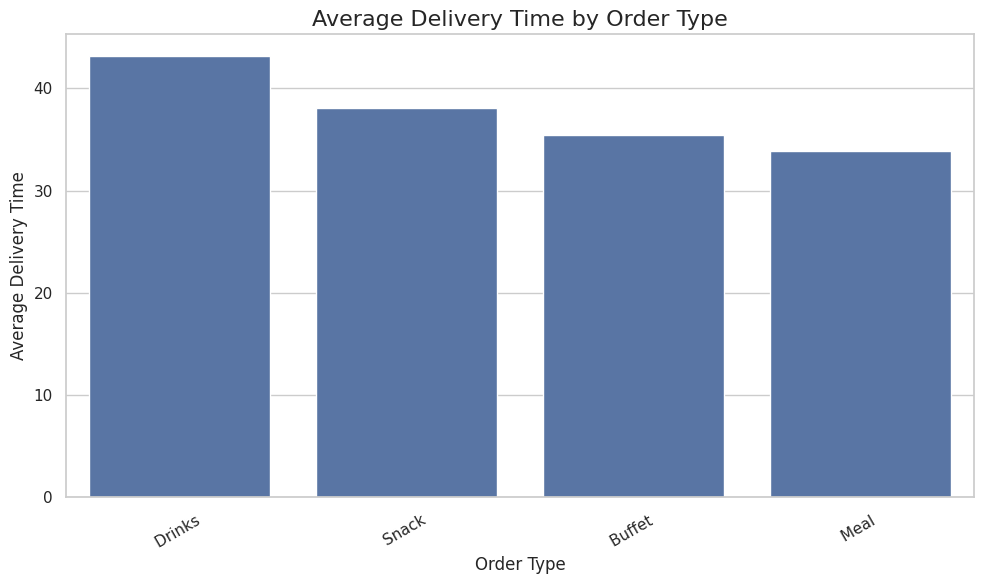

In [ ]:

order_data = df_clean.dropna(
    subset=["Delivery Time"]
).copy()

order_data = order_data[
    order_data["Order Type"] != "Unknown"
]

order_analysis = order_data.groupby("Order Type").agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median"),
    Minimum_Delivery_Time=("Delivery Time", "min"),
    Maximum_Delivery_Time=("Delivery Time", "max")
).round(2)

order_analysis = order_analysis.sort_values(
    by="Average_Delivery_Time",
    ascending=False
)

display(order_analysis)
plt.figure(figsize=(10, 6))

sns.barplot(
    data=order_data,
    x="Order Type",
    y="Delivery Time",
    errorbar=None,
    order=order_analysis.index
)

plt.title("Average Delivery Time by Order Type", fontsize=16)
plt.xlabel("Order Type")
plt.ylabel("Average Delivery Time")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Traffic Level Analysis


Delivery Statistics by Traffic Level:


,Total_Deliveries,Average_Delivery_Time,Median_Delivery_Time,Minimum_Delivery_Time,Maximum_Delivery_Time
Traffic Level,,,,,
Very High,1748,62.26,59.41,46.03,157.75
High,2730,42.76,42.68,31.03,59.17
Moderate,2212,31.34,31.10,21.08,44.58
Low,1718,21.40,21.29,11.00,34.20
Very Low,632,13.89,13.02,5.80,24.57


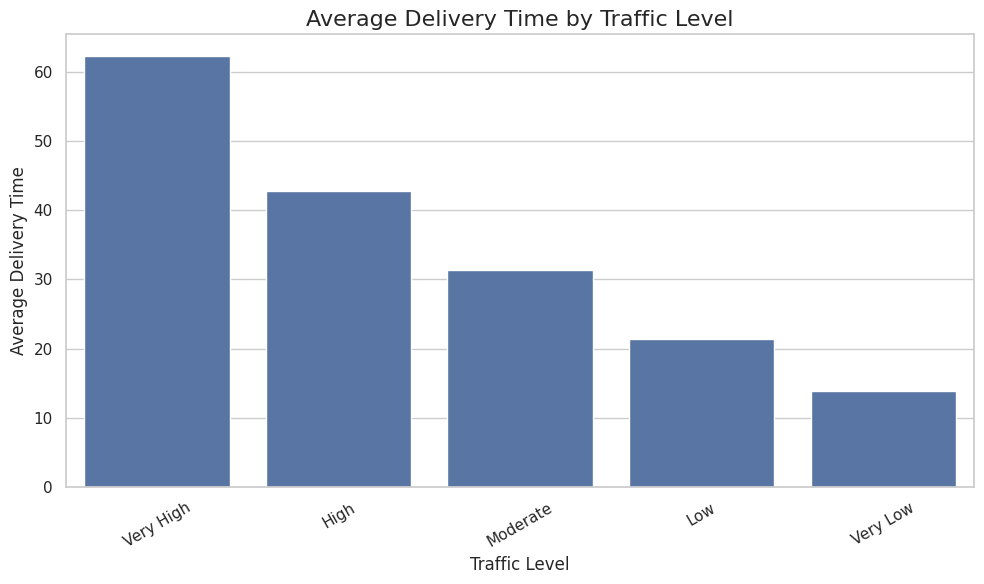

In [ ]:

traffic_data = df_clean.dropna(
    subset=["Delivery Time"]
).copy()

traffic_data = traffic_data[
    traffic_data["Traffic Level"] != "Unknown"
]

traffic_analysis = traffic_data.groupby("Traffic Level").agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median"),
    Minimum_Delivery_Time=("Delivery Time", "min"),
    Maximum_Delivery_Time=("Delivery Time", "max")
).round(2)

traffic_analysis = traffic_analysis.sort_values(
    by="Average_Delivery_Time",
    ascending=False
)

print("\nDelivery Statistics by Traffic Level:")
display(traffic_analysis)

traffic_order = traffic_analysis.index.tolist()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=traffic_data,
    x="Traffic Level",
    y="Delivery Time",
    order=traffic_order,
    errorbar=None
)

plt.title("Average Delivery Time by Traffic Level", fontsize=16)
plt.xlabel("Traffic Level")
plt.ylabel("Average Delivery Time")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Weather Analysis


Delivery Statistics by Weather:


,Total_Deliveries,Average_Delivery_Time,Median_Delivery_Time,Minimum_Delivery_Time,Maximum_Delivery_Time
Weather Description,,,,,
moderate rain,1,66.45,66.45,66.45,66.45
overcast clouds,182,61.42,60.33,35.30,86.68
fog,49,52.70,52.08,37.85,78.67
smoke,498,44.16,42.82,13.08,94.60
scattered clouds,409,43.87,40.97,8.18,101.00
clear sky,3211,39.11,38.30,5.80,157.75
broken clouds,532,37.73,36.22,7.45,105.95
few clouds,40,36.99,36.63,11.55,63.35
mist,1740,34.60,33.01,8.27,92.18


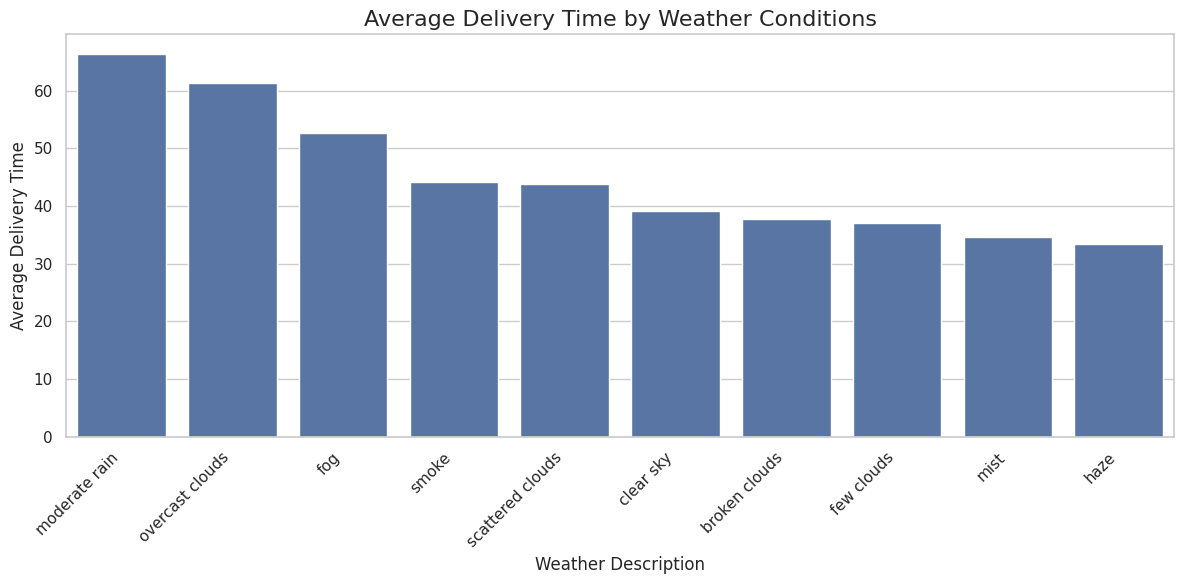

In [ ]:

weather_data = df_clean.dropna(
    subset=["Delivery Time"]
).copy()

weather_data = weather_data[
    weather_data["Weather Description"] != "Unknown"
]

weather_analysis = weather_data.groupby(
    "Weather Description"
).agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median"),
    Minimum_Delivery_Time=("Delivery Time", "min"),
    Maximum_Delivery_Time=("Delivery Time", "max")
).round(2)

weather_analysis = weather_analysis.sort_values(
    by="Average_Delivery_Time",
    ascending=False
)

print("\nDelivery Statistics by Weather:")
display(weather_analysis)

weather_order = weather_analysis.index.tolist()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=weather_data,
    x="Weather Description",
    y="Delivery Time",
    order=weather_order,
    errorbar=None
)

plt.title("Average Delivery Time by Weather Conditions", fontsize=16)
plt.xlabel("Weather Description")
plt.ylabel("Average Delivery Time")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Distance vs. Delivery Time


Valid Records for Analysis: 9035
Distance-Time Correlation: 0.869


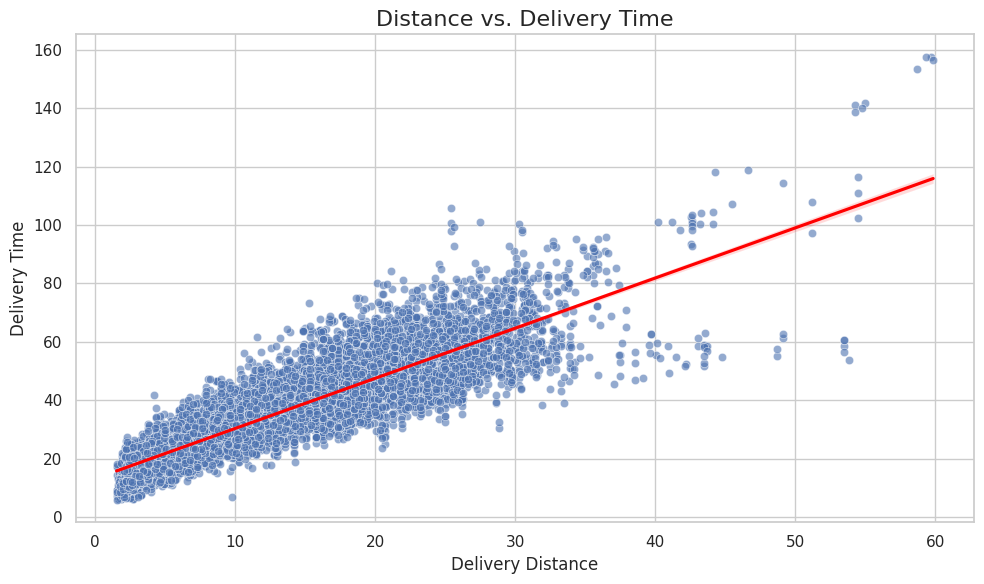

In [ ]:

distance_data = df_clean.dropna(
    subset=["Distance", "Delivery Time"]
).copy()

distance_data = distance_data[
    (distance_data["Distance"] >= 0) &
    (distance_data["Delivery Time"] >= 0)
]

print("\nValid Records for Analysis:", len(distance_data))

correlation = distance_data[
    ["Distance", "Delivery Time"]
].corr().loc["Distance", "Delivery Time"]

print(f"Distance-Time Correlation: {correlation:.3f}")

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=distance_data,
    x="Distance",
    y="Delivery Time",
    alpha=0.6
)

sns.regplot(
    data=distance_data,
    x="Distance",
    y="Delivery Time",
    scatter=False,
    color="red"
)

plt.title("Distance vs. Delivery Time", fontsize=16)
plt.xlabel("Delivery Distance")
plt.ylabel("Delivery Time")

plt.tight_layout()
plt.show()

Vehicle Type Analysis


Vehicle Performance Summary:


,Total_Deliveries,Average_Delivery_Time,Median_Delivery_Time,Average_Distance,Average_Rating
Vehicle Type,,,,,
scooter,2971,37.82,36.20,14.39,4.63
motorcycle,5350,37.66,36.00,14.26,4.62
electric scooter,709,36.99,35.07,13.99,4.66
bicycle,10,31.40,27.79,12.00,3.88


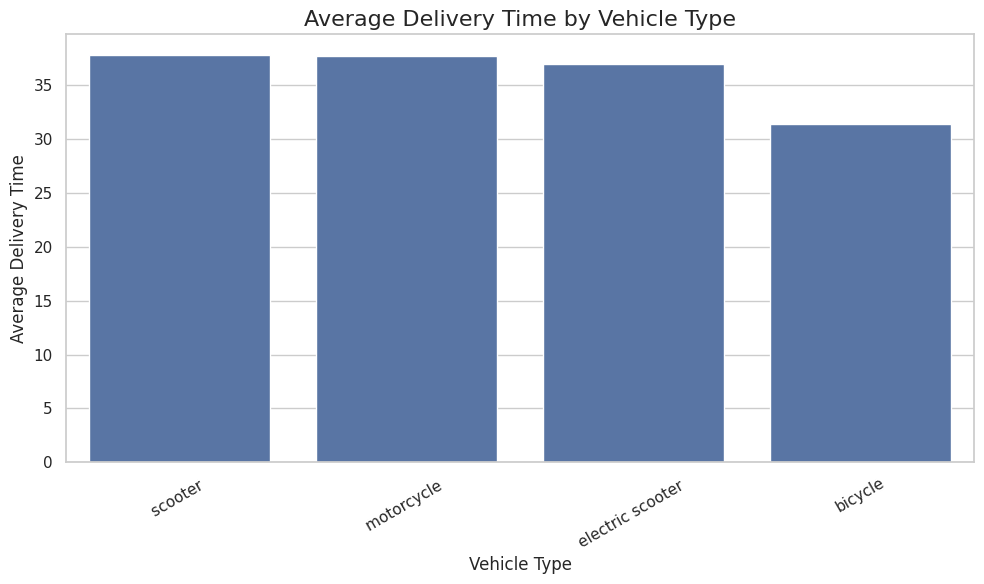

In [ ]:

vehicle_data = df_clean.dropna(
    subset=["Delivery Time"]
).copy()

vehicle_data = vehicle_data[
    vehicle_data["Vehicle Type"] != "Unknown"
]

vehicle_analysis = vehicle_data.groupby("Vehicle Type").agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median"),
    Average_Distance=("Distance", "mean"),
    Average_Rating=("Delivery Person Ratings", "mean")
).round(2)

# Sort by average delivery time
vehicle_analysis = vehicle_analysis.sort_values(
    by="Average_Delivery_Time",
    ascending=False
)

print("\nVehicle Performance Summary:")
display(vehicle_analysis)

# Visualize average delivery time by vehicle type
vehicle_order = vehicle_analysis.index.tolist()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=vehicle_data,
    x="Vehicle Type",
    y="Delivery Time",
    order=vehicle_order,
    errorbar=None
)

plt.title("Average Delivery Time by Vehicle Type", fontsize=16)
plt.xlabel("Vehicle Type")
plt.ylabel("Average Delivery Time")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Delivery Person Ratings Analysis


Delivery Time by Rating Category:


,Total_Deliveries,Average_Delivery_Time,Median_Delivery_Time
Rating_Category,,,
Low (0-3),27,48.59,47.77
Medium (3-4),469,43.65,42.33
High (4-5),8541,37.29,35.52



Rating-Time Correlation: -0.100


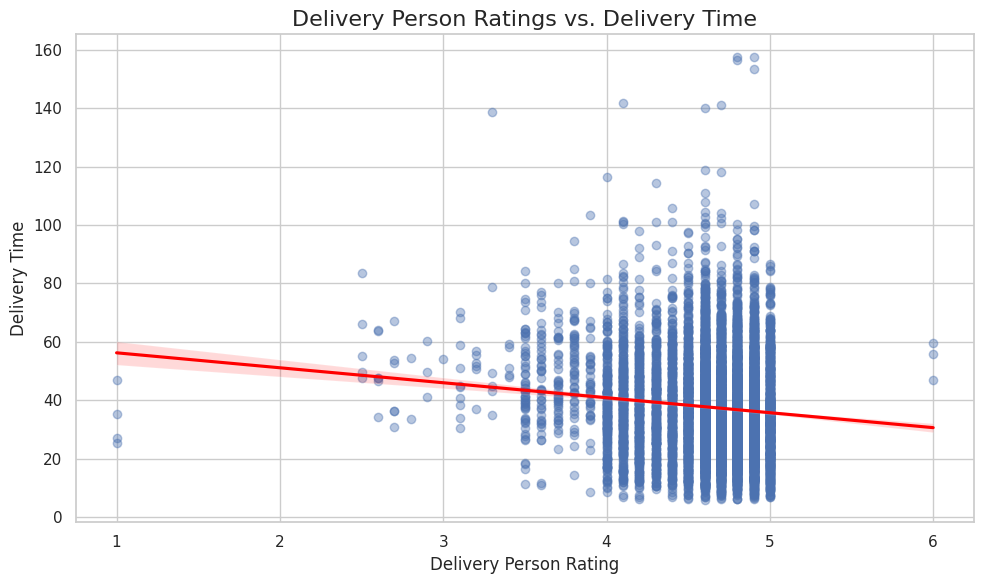

In [ ]:

rating_data = df_clean.dropna(
    subset=["Delivery Person Ratings", "Delivery Time"]
).copy()

rating_data = rating_data[
    rating_data["Delivery Time"] >= 0
]

rating_data["Rating_Category"] = pd.cut(
    rating_data["Delivery Person Ratings"],
    bins=[0, 3, 4, 5],
    labels=["Low (0-3)", "Medium (3-4)", "High (4-5)"],
    include_lowest=True
)

rating_analysis = rating_data.groupby(
    "Rating_Category",
    observed=False
).agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median")
).round(2)

print("\nDelivery Time by Rating Category:")
display(rating_analysis)

correlation = rating_data[
    ["Delivery Person Ratings", "Delivery Time"]
].corr().iloc[0, 1]

print(f"\nRating-Time Correlation: {correlation:.3f}")

plt.figure(figsize=(10, 6))

sns.regplot(
    data=rating_data,
    x="Delivery Person Ratings",
    y="Delivery Time",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Delivery Person Ratings vs. Delivery Time", fontsize=16)
plt.xlabel("Delivery Person Rating")
plt.ylabel("Delivery Time")

plt.tight_layout()
plt.show()

Final Business Insights

In [ ]:
# 1. Overall delivery performance
valid_times = df_clean["Delivery Time"].dropna()
valid_distances = df_clean["Distance"].dropna()

print("\n1. OVERALL DELIVERY PERFORMANCE")

print(f"Total delivery records: {len(df_clean)}")
print(f"Records with delivery time: {len(valid_times)}")
print(f"Records with distance: {len(valid_distances)}")

if not valid_times.empty:
    print(f"Average delivery time: {valid_times.mean():.2f}")
    print(f"Median delivery time: {valid_times.median():.2f}")

if not valid_distances.empty:
    print(f"Average delivery distance: {valid_distances.mean():.2f}")

# 2. Order type insights
print("\n2. ORDER TYPE INSIGHTS")

order_data = df_clean.dropna(subset=["Delivery Time"])
order_data = order_data[order_data["Order Type"] != "Unknown"]

if not order_data.empty:
    order_avg = order_data.groupby("Order Type")["Delivery Time"].mean()
    print(f"Highest average delivery time: {order_avg.idxmax()}")
    print(f"Lowest average delivery time: {order_avg.idxmin()}")

# 3. Traffic insights
print("\n3. TRAFFIC INSIGHTS")

traffic_data = df_clean.dropna(subset=["Delivery Time"])
traffic_data = traffic_data[traffic_data["Traffic Level"] != "Unknown"]

if not traffic_data.empty:
    traffic_avg = traffic_data.groupby("Traffic Level")["Delivery Time"].mean()
    print(f"Highest average delivery time: {traffic_avg.idxmax()}")
    print(f"Lowest average delivery time: {traffic_avg.idxmin()}")

# 4. Weather insights
print("\n4. WEATHER INSIGHTS")

weather_data = df_clean.dropna(subset=["Delivery Time"])
weather_data = weather_data[weather_data["Weather Description"] != "Unknown"]

if not weather_data.empty:
    weather_avg = weather_data.groupby(
        "Weather Description"
    )["Delivery Time"].mean()

    print(f"Highest average delivery time: {weather_avg.idxmax()}")
    print(f"Lowest average delivery time: {weather_avg.idxmin()}")

# 5. Vehicle insights
print("\n5. VEHICLE INSIGHTS")

vehicle_data = df_clean.dropna(subset=["Delivery Time"])
vehicle_data = vehicle_data[vehicle_data["Vehicle Type"] != "Unknown"]

if not vehicle_data.empty:
    vehicle_avg = vehicle_data.groupby("Vehicle Type")["Delivery Time"].mean()
    print(f"Highest average delivery time: {vehicle_avg.idxmax()}")
    print(f"Lowest average delivery time: {vehicle_avg.idxmin()}")

# 6. Distance and delivery time relationship
print("\n6. DISTANCE ANALYSIS")

distance_data = df_clean.dropna(
    subset=["Distance", "Delivery Time"]
)

distance_data = distance_data[
    (distance_data["Distance"] >= 0) &
    (distance_data["Delivery Time"] >= 0)
]

if len(distance_data) >= 2:
    correlation = distance_data[
        ["Distance", "Delivery Time"]
    ].corr().iloc[0, 1]

    print(f"Distance-time correlation: {correlation:.3f}")

    if correlation > 0.5:
        print("Observation: Strong positive linear association.")
    elif correlation > 0:
        print("Observation: Positive linear association.")
    elif correlation < -0.5:
        print("Observation: Strong negative linear association.")
    elif correlation < 0:
        print("Observation: Negative linear association.")
    else:
        print("Observation: Little or no linear association.")



1. OVERALL DELIVERY PERFORMANCE
Total delivery records: 10000
Records with delivery time: 9040
Records with distance: 9080
Average delivery time: 37.66
Median delivery time: 35.98
Average delivery distance: 14.29

2. ORDER TYPE INSIGHTS
Highest average delivery time: Drinks 
Lowest average delivery time: Meal 

3. TRAFFIC INSIGHTS
Highest average delivery time: Very High
Lowest average delivery time: Very Low

4. WEATHER INSIGHTS
Highest average delivery time: moderate rain
Lowest average delivery time: haze

5. VEHICLE INSIGHTS
Highest average delivery time: scooter 
Lowest average delivery time: bicycle

6. DISTANCE ANALYSIS
Distance-time correlation: 0.869
Observation: Strong positive linear association.


Final Data Quality Validation

In [ ]:
# 1. Dataset dimensions
print("\n1. Dataset Shape:")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

# 2. Remaining missing values
print("\n2. Missing Values:")
missing_values = df_clean.isnull().sum()
print(missing_values[missing_values > 0])

print("Total Missing Values:", df_clean.isnull().sum().sum())

# 3. Duplicate rows
print("\n3. Duplicate Rows:")
print(df_clean.duplicated().sum())

# 4. Duplicate IDs
print("\n4. Duplicate Delivery IDs:")
print(df_clean["ID"].duplicated().sum())

# 5. Check important numeric columns
print("\n5. Numeric Column Validation:")

numeric_columns = [
    "Delivery Person Age",
    "Delivery Person Ratings",
    "Temperature",
    "Humidity",
    "Precipitation",
    "Distance",
    "Delivery Time"
]

for column in numeric_columns:
    invalid_count = (df_clean[column] < 0).sum()
    print(f"{column}: {invalid_count} negative values")

# 6. Check delivery time and distance availability
print("\n6. Analysis Data Availability:")
print(
    "Valid Delivery Times:",
    df_clean["Delivery Time"].notna().sum()
)
print(
    "Valid Distances:",
    df_clean["Distance"].notna().sum()
)

# 7. Final validation status
print("\n7. Validation Summary:")

if df_clean["ID"].duplicated().sum() == 0:
    print("No duplicate delivery IDs detected.")
else:
    print("Warning: Duplicate delivery IDs detected.")

if df_clean.duplicated().sum() == 0:
    print("No duplicate rows detected.")
else:
    print("Warning: Duplicate rows detected.")

print("\nValidation completed!")



1. Dataset Shape:
Rows: 10000
Columns: 17

2. Missing Values:
Distance         920
Delivery Time    960
dtype: int64
Total Missing Values: 1880

3. Duplicate Rows:
0

4. Duplicate Delivery IDs:
9

5. Numeric Column Validation:
Delivery Person Age: 0 negative values
Delivery Person Ratings: 0 negative values
Temperature: 0 negative values
Humidity: 0 negative values
Precipitation: 0 negative values
Distance: 0 negative values
Delivery Time: 0 negative values

6. Analysis Data Availability:
Valid Delivery Times: 9040
Valid Distances: 9080

7. Validation Summary:
No duplicate rows detected.

Validation completed!


Export Cleaned Dataset and Analysis Results

In [ ]:


from google.colab import files
import os

output_folder = "food_delivery_results"
os.makedirs(output_folder, exist_ok=True)

# 2. Export cleaned dataset
cleaned_file = os.path.join(
    output_folder,
    "cleaned_food_delivery_dataset.csv"
)

df_clean.to_csv(cleaned_file, index=False)
print("Cleaned dataset exported successfully!")

# 3. Export descriptive statistics
statistics_file = os.path.join(
    output_folder,
    "descriptive_statistics.csv"
)

df_clean.describe().T.round(2).to_csv(statistics_file)
print("Descriptive statistics exported successfully!")

# 4. Export order type analysis
order_data = df_clean.dropna(subset=["Delivery Time"])
order_data = order_data[order_data["Order Type"] != "Unknown"]

order_results = order_data.groupby("Order Type").agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median")
).round(2)

order_results.to_csv(
    os.path.join(output_folder, "order_type_analysis.csv")
)
print("Order type analysis exported successfully!")

# 5. Export traffic analysis
traffic_data = df_clean.dropna(subset=["Delivery Time"])
traffic_data = traffic_data[traffic_data["Traffic Level"] != "Unknown"]

traffic_results = traffic_data.groupby("Traffic Level").agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median")
).round(2)

traffic_results.to_csv(
    os.path.join(output_folder, "traffic_analysis.csv")
)
print("Traffic analysis exported successfully!")

# 6. Export weather analysis
weather_data = df_clean.dropna(subset=["Delivery Time"])
weather_data = weather_data[
    weather_data["Weather Description"] != "Unknown"
]

weather_results = weather_data.groupby(
    "Weather Description"
).agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median")
).round(2)

weather_results.to_csv(
    os.path.join(output_folder, "weather_analysis.csv")
)
print("Weather analysis exported successfully!")

# 7. Export vehicle analysis
vehicle_data = df_clean.dropna(subset=["Delivery Time"])
vehicle_data = vehicle_data[vehicle_data["Vehicle Type"] != "Unknown"]

vehicle_results = vehicle_data.groupby("Vehicle Type").agg(
    Total_Deliveries=("ID", "count"),
    Average_Delivery_Time=("Delivery Time", "mean"),
    Median_Delivery_Time=("Delivery Time", "median")
).round(2)

vehicle_results.to_csv(
    os.path.join(output_folder, "vehicle_analysis.csv")
)
print("Vehicle analysis exported successfully!")

# 8. Create ZIP archive
import shutil

shutil.make_archive(
    "food_delivery_results",
    "zip",
    output_folder
)

print("\nAll results exported successfully!")
print("ZIP file: food_delivery_results.zip")

# 9. Download ZIP archive
files.download("food_delivery_results.zip")

Cleaned dataset exported successfully!
Descriptive statistics exported successfully!
Order type analysis exported successfully!
Traffic analysis exported successfully!
Weather analysis exported successfully!
Vehicle analysis exported successfully!

All results exported successfully!
ZIP file: food_delivery_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>